# Task 4: Game Title Detection — Final V5 Single-File End-to-End Pipeline

**CPE342 Machine Learning (1/2026) — Team ML009**
- **Task:** 5-Class Image Classification (`0=7-11K`, `1=FiveN`, `2=FreeFried`, `3=PUBE`, `4=Roblock`)
- **Evaluation Metric:** Macro $F_1$-Score (`31,546` Train / `25,889` Test, `230x120` RGB)
- **Complete Self-Contained End-to-End Architecture:**
  - **Benchmark:** Embedded `Golden Unseen-Scene 5-Fold CV` (`418` spherical clusters via `StratifiedGroupKFold`, slashing high-similarity scene overlap `>=0.85` from `10.95%` to `5.03%`)
  - **Restoration:** Visually Verified Seam-Free & Noise-Safe 4-View GPU Restoration (`std_c >= 0.075` + `snr_w` taper + corner-safe luminance normalization)
  - **Phase 1 (`5-Foundation MLP`):** 4-View Embeddings from `DINOv2-S`, `SigLIP2-B`, `EVA02-CLIP-B`, `ConvNeXt-T`, `EffNetV2-S` + 24 physical features -> `ResidualEmbeddingNet` (`0.94045`)
  - **Phase 2 (`E2E Domain-Hardened Fine-Tuning`):** `ConvNeXt-Small` (`128x256`) + `Swin-Tiny` (`224x224`) with GPU Aspect-Preserving Affine Rotation `±35°`, Dark Gamma, Shot Noise, Cutout, MixUp, FP32 Softmax & 4-View TTA (no toxic VFlip!)
  - **Phase 3 (`Calibrated Ensemble`):** Out-of-Fold PyTorch `L-BFGS` Temperature Scaling + 3-Family Logit Blend (`0.50 ConvNeXt-Small + 0.35 Swin-Tiny + 0.15 5-Foundation MLP`) -> exports `submissions/sub_task4.csv`
- **Verified Cloud L4 Execution Results (Kaggle Total LB `0.83963 -> 0.85209`):**
  - Golden Unseen-Scene **`AllF1 = 0.98036`**, **`BalF1 = 0.97909`**
  - Slice Robustness: **`Dark<45 = 0.9403`** (`+0.2044` vs V3), **`Border Rot = 0.9695`**, **`Noise = 0.9779`**
  - Test Disagreement (`ConvNeXt-Small vs Swin-Tiny`): `9.23%`, Mean Confidence: `0.8978`, Test Class Counts: `{0: 4196, 1: 6000, 2: 3991, 3: 6709, 4: 4993}`

> **หมายเหตุการรันซ้ำ:** โน้ตบุ๊กไฟล์นี้รวมโค้ด Phase 1, 2 และ 3 ไว้ครบในไฟล์เดียว สามารถเปิดรันตั้งแต่ Cell แรกบน **Google Colab L4 GPU** หรือ Kaggle GPU เพื่อเทรนและสร้าง `sub_task4.csv` ได้อัตโนมัติ

In [1]:
# [Cell 1] Environment Check, Dependencies & Paths
import os, sys, io, gc, time, glob, zlib, base64, random, shutil, zipfile, warnings
warnings.filterwarnings("ignore")

IN_KAGGLE = os.path.exists("/kaggle/working")
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

import subprocess
def _pip_ensure(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", pkg], check=False)

try:
    import timm
    if tuple(int(x) for x in timm.__version__.split(".")[:2]) < (1, 0):
        _pip_ensure("timm>=1.0.15")
except ImportError:
    _pip_ensure("timm>=1.0.15")

try:
    import gdown
except ImportError:
    if IN_COLAB or IN_KAGGLE:
        _pip_ensure("gdown")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import timm
from PIL import Image
from sklearn.metrics import f1_score, log_loss, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

cwd = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(cwd, "data", "task4", "train.csv")):
    BASE_DIR = cwd
elif os.path.exists(os.path.join(os.path.dirname(cwd), "data", "task4", "train.csv")):
    BASE_DIR = os.path.dirname(cwd)
else:
    BASE_DIR = cwd

OUT_DIR = (
    "/kaggle/working/task4_cloud_out" if IN_KAGGLE else
    "/content/task4_cloud_out" if IN_COLAB else
    os.path.join(BASE_DIR, "task4", "cloud_outputs")
)
SUB_DIR = os.path.join(BASE_DIR, "submissions") if not (IN_COLAB or IN_KAGGLE) else OUT_DIR
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

assert torch.cuda.is_available(), "Task 4 full training requires a CUDA GPU (recommended: Google Colab L4 24GB or T4)."
DEVICE = torch.device("cuda")
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
BS_SCALE = 2 if VRAM_GB >= 22.0 else 1
print(f"Environment : {'Kaggle' if IN_KAGGLE else 'Colab' if IN_COLAB else 'Local'} | PyTorch={torch.__version__} | timm={timm.__version__}")
print(f"GPU         : {torch.cuda.get_device_name(0)} ({VRAM_GB:.2f} GB VRAM, bs_scale={BS_SCALE})")
print(f"OUT_DIR     : {OUT_DIR}")
print(f"SUB_DIR     : {SUB_DIR}")

Environment : Colab | PyTorch=2.14.1+cu130 | timm=1.0.31
GPU         : NVIDIA L4 (23.66 GB VRAM, bs_scale=2)
OUT_DIR     : /content/task4_cloud_out
SUB_DIR     : /content/task4_cloud_out


## 1. Automatic Dataset Locator (`data/task4` / Google Drive / Kaggle Input)

In [2]:
# [Cell 2] Bulletproof Task 4 Data Locator (Kaggle Input / Google Drive / Official Drive ID)
OFFICIAL_GDRIVE_URL = "https://drive.google.com/file/d/1C8csylbBo3Oab24ODGKPVom3_SDUJ_Qw/view?usp=share_link"
WORK_DATA_ROOT = "/kaggle/working/task4_data" if IN_KAGGLE else "/content/task4_data"
os.makedirs(WORK_DATA_ROOT, exist_ok=True)

def find_valid_task4_dir(root_paths):
    for root in root_paths:
        if not os.path.exists(root):
            continue
        for cur, dirs, files in os.walk(root):
            if "__MACOSX" in cur:
                continue
            if "train.csv" in files and "test.csv" in files:
                has_imgs = os.path.isdir(os.path.join(cur, "train")) and os.path.isdir(os.path.join(cur, "test"))
                if has_imgs:
                    # Verify train/ actually contains jpgs
                    n_jpg = len(os.listdir(os.path.join(cur, "train")))
                    if n_jpg > 30000:
                        return cur
    return None

DATA_DIR = find_valid_task4_dir([os.path.join(BASE_DIR, "data", "task4"), WORK_DATA_ROOT, "/kaggle/input", "/content"])

DRIVE_BACKUP_DIR = "/content/drive/MyDrive/cpe342_task4_outputs" if os.path.exists("/content/drive/MyDrive") else None
if DRIVE_BACKUP_DIR:
    os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

if DATA_DIR is None and os.path.exists("/content/drive/MyDrive"):
    for cand_zip in [
        "/content/drive/MyDrive/task4_data.zip",
        "/content/drive/MyDrive/task4.zip",
        "/content/drive/MyDrive/cpe342_task4.zip",
        "/content/drive/MyDrive/Kaggle/task4_data.zip",
    ]:
        if os.path.exists(cand_zip):
            print(f"Found zip in mounted Google Drive: {cand_zip} -> extracting...", flush=True)
            with zipfile.ZipFile(cand_zip, "r") as zf:
                zf.extractall(WORK_DATA_ROOT)
            DATA_DIR = find_valid_task4_dir([WORK_DATA_ROOT])
            break
    if DATA_DIR is None:
        DATA_DIR = find_valid_task4_dir(["/content/drive/MyDrive"])

if DATA_DIR is None:
    import gdown
    zip_dl = os.path.join(WORK_DATA_ROOT, "task4_official.zip")
    if not os.path.exists(zip_dl):
        print("Downloading Task 4 dataset from official competition Drive link (no OAuth popup)...", flush=True)
        ok = gdown.download(url=OFFICIAL_GDRIVE_URL, output=zip_dl, fuzzy=True, quiet=False)
        if not ok or not os.path.exists(zip_dl):
            raise RuntimeError(
                "GDOWN_QUOTA_OR_FAIL: ดาวน์โหลดจากลิงก์กลางไม่สำเร็จหรือติดโควตา Google Drive ชั่วคราว "
                "แนะนำให้อัปโหลด task4_data.zip ขึ้น Google Drive ส่วนตัวแล้ว mount /content/drive หรือรันจาก Local Zip ครับ"
            )
    print(f"Extracting {zip_dl} (ignoring __MACOSX)...", flush=True)
    with zipfile.ZipFile(zip_dl, "r") as zf:
        members = [m for m in zf.namelist() if "__MACOSX" not in m]
        zf.extractall(WORK_DATA_ROOT, members=members)
    DATA_DIR = find_valid_task4_dir([WORK_DATA_ROOT])

assert DATA_DIR is not None, "ไม่พบโฟลเดอร์ที่มี train.csv, test.csv, train/, test/ กรุณาตรวจสอบพาธข้อมูล"
tr_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
te_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
assert len(tr_df) == 31546 and len(te_df) == 25889, f"Unexpected row counts: {len(tr_df)}, {len(te_df)}"
y_all = tr_df["label"].to_numpy().astype(np.int64)
print(f"Verified Task 4 DATA_DIR: {DATA_DIR}")
print(f"Train={len(tr_df):,} | Test={len(te_df):,} | Class Counts={np.bincount(y_all).tolist()}")

Downloading...
From (original): https://drive.google.com/uc?id=1C8csylbBo3Oab24ODGKPVom3_SDUJ_Qw
From (redirected): https://drive.google.com/uc?id=1C8csylbBo3Oab24ODGKPVom3_SDUJ_Qw&confirm=t&uuid=974c31df-e84d-45ea-be30-eb0515f90bf5
To: /content/task4_data/task4_official.zip
100%|██████████| 626M/626M [00:09<00:00, 64.4MB/s]

Extracting /content/task4_data/task4_official.zip (ignoring __MACOSX)...


Verified Task 4 DATA_DIR: /content/task4_data
Train=31,546 | Test=25,889 | Class Counts=[12429, 4407, 5596, 5926, 3188]


## 2. Embedded Golden Unseen-Scene 5-Fold Split, RAM JPEG Preload & 24 Physical Features

In [3]:
# [Cell 3] Embedded Golden Unseen-Scene 5-Fold Split + RAM JPEG Preload + 24 Phys Features
FOLDS_SCENE_B64 = """
eNpNnQl2JLmOBInl/meuoJkzVX/edKulXCJIEHA4HIiz22f69Pev09+/p2q+/5g6u1Wnvr+e+n78/rO3ennl1Pii6u+H2a4z
U/v9OPO9q3u69/vN95nf//d9Vy3//F7y/d/38u8zvj/O/XXV1ve2uV/1fdT39nsNdd93v2rz1+9/3/ee813u/c33/u+N5/vh
/v67tO/zvn9+b/6+ub///D7su4K539rfS+/7mju8r/5e+12rV/d92577q3OXYryU+9XfLX8f8P37u9C5t3vv+3722e/aq1iu
vZd4v+te+t7lu9dxL3nv1Z17sXN/830HP3/f+v3y++rvK7iIe4vfd91bqPsmlvl74/eS+0Pdrz/38u7H3PX/vm7uZXPx94Xn
fuTdqLuSbMa5n913k87dF+547hotG3BY9/tL/nTXclj5ez9s8bJkfEEfX3w/p1jw4bbvF9+d5gK/v1x7ubtx2ASs5fvnvfO7
PvdC614mi/wt0Pel44LfH++9fm/OVR6vd1iL76ruHjZGmOX5tve7k7k3zg58b977+vuq73oLS6liF7FQrpHN/t587WzZ3mJ5
WOO931LcBNt0P9TFu5fAImA1517fNe+743dFjxs69+pY+cIkv6+9C3ht624nO3ENRIvno76X7f3dfe+9j+Jg3Au7H34N4h6v
e+F+ePsHV7Ex+nsrhwU5GM9di7uE93MxlPuF3x3cJT5YmPt8MNZ7qr+rnGm3+q48ptAc5buEzSkq9vYemOYwDdtxTfDe/2AM
d+UxiMkVFsf32sd9iXvDjtRdFs2pMMXWkbD895jeeypO1/VN18C//+31VdzdPUfHL7iH7J6Pey41oGax3QlOXGuSugxW8d4R
Nr86HK3hftvdtmbF7sffU3rvsDn1987ffVyj/HYCh6bPuvt47Y9tn+ugDtZcHuDr6q4/uGfyeqX2TboqHM5dhutr7y0UFn0X
ubkvLMsTM5xZznddf8FqTVwNLhWH1RjI3cB73xzD5vf3VC8uB7+83E6xAdxbcd9e/vVK3jVbdvj/yULd28C33lM6HA7M4BoK
7+ZDC+O7x/Ve4z0oBIh7dffMYCnrul6b5BoG69iEh7MxjHuMro3d1bmLfl97v+qa8V2tu/iLixi34i7P4FDuGt7bHeLPfQGW
Ndiy8Qnfca8AX9LrZ9wzeo/3PXo4Or6bdbprYswZjixmsl7Qvdv7xnuz5Qd8v7k7UMt+tHu37OcaKO9VaggcCVyExng//VwD
xdfdy7puh2M+mPVmc7Azrux+nkHlGGEMXyfBieXF1K6NEgCKg3G9KA5YB3Dv94a6e0eNV+YrDH944NbkO/5aa7iGNTj++1GL
E8GiuQjizl29LRd7jgGAQO7yYGM48sOrsR3dLz6On3DU16bKc+j3Y7mx6ruTh5BNCLlxa6+dXbu7F/JniER8gtEZV/GaHocM
T8IHH2LP3ZN7LbpYgknXs24cUI+nDkcEimqt0rh1o3vjz3QtxLRrHqXJHEy3CM3D0h08nQ7uJCpc33V46f0bgfV+xLX/Bjlw
yW5ug7EwlYp13MMAqCM4ExPuVgqwFvRwl0OXfMAchyXBW/gN/FKggVXcZV8sC/RHGGBjQR7LOQIKXFP1dnnttXW9PnZLCL+X
Oqzu3eTOkfUqAAlAMhbJOEqwvudu/sAsYZfYcK+DcFX8CUx1P7oNj0YTzPx+H3t5TUGnsWzs4ZguFxs3Elc/ogbW9x6Nw8HU
3FkZnPjBb+ODFjfJRRDT7idfIyhwopHz+td7YevxXW7SOL7lC0dYsXr266tGq0kc9nLXPbyLyNdwQLBwLAUIarC833GtE9y+
vPRwt2f1YOcEUvElo3vV0RFRWL/WH4Bwii3ARYiYjd7gI07h8Q61lXtBwHHxOot0N4ftxG72IQ7A4AJBiKD4//zsQcVGDdRv
hQ5WyWkGTQSoHi0bd6470KnkrOV4rdtxbdCYf08U3rvIKvA5+Mksw71sr3F1rqQn2NYhSTIMc+4AnXzRfQ0GMX4hxxgPhQ3p
pK8hcNOzgnk+ocUtpkoL+E8adXdGfA/y4WZI7wzQmGD7Ir19mYCRDOnqMcwj4ARbFJiTyMsx0GsTRbnpWk8ZbwY7BgoQuMA+
JyFwjFN4To9R7JFMszijpW85+ssbXMiPAKyHZA8Ez6kCLbVHGhw5nAPDIdjRJeykWEdUBAR66R++AZA3Yg6ug4juOXDxx6T2
nkod1j32LQaoeSCyyFSGXJDQxyke4SRWohvhLprAeFfmLl7htnCYOGj2sHB4+AwQKvj/Wv0Aq0l7R7zpkU2SckECb3YHue+7
JuysGBlkbVhjVcoEGid9s5LGmZuyFAkhZ86ki+wL6MSBw/kQu+6SEHeD6QyW+k0tZs08dJiegGOgFEKzA/ccEJ4wJXJGgKVY
qD1gNaYou55JM0T+wCkBR2OjJoQSFwTn+wlsivCzJQpItPhqHKHOoAjluA0yo0N6Yuo3MiTXXHY1pu3sHznRAjH4eEL4gUFx
+UsPDJDFIJMYL7HDs8n6yplwjtz5gvsYsIWvIH6vyA17vEhFCLtQFnwRcT7g01MvuvKI3ZUWnVxfahLEoW+/1QvC5xIuMBEg
BckW3ADrD9AdgashsF6KqjteAsAmIFUl3gLJ4ahIpGvEikdOxXCB4yjRt7Ev6PdoCYMNubGDGyN74TC4H01IBLfMPBzOzeLL
7wI1SIs4rTM/9Y4X1v4CyD0Xza2JVM4IAIZ/wDJwso/cG3no/YJz8h06rOGDBkcBAILzALwQccDBor7FB4Zfwq9gKQcuZsQm
Jm4F6zHuXXPAKin/aT9KDMjOckX9IApZT5yUie91KXhT3eiYDkGm1bMrfPW9jhdPcf+hEnCJpDjH9AesvMAUDHjFobg7rJRv
JFtqwCgbAUQqgTHXb84nR0YOjbmyPGBq6BOZNikNgUnJzfCKe+IgfqrM2P0KEhScDvYsYcZ56TBe99ySdIxRUsiCx6jQQyyk
jN5dSvBBABsEXZvo4ZJECmBYI/RIGGGJ7NeMKXbpnM9o4WBCyMEtCbkTrpTfh3sobo3ExFygdWLmE0caAHOX9hvhD7m32MzT
u+XNy/foUcHMmhYIkbCCDbR5GF5o+pFo3g/brDF3sr4y5ayYA8FRUuoe4ZJ1bUPX0Y/jwZozYNDucM9mIxgARDMhm+sx3WXP
yU4ubjXJAf+s7Nk98AAx9uOIwXVF9xaBrmSm60+TQPGIM5ACsdgsnwjGp2FvRAAR0DFlgpTFwuX9uN1JktIELpK2gSeCO8Ak
IJnEF9UdI8Nakrhf7zgv11vz3mvQxs0jgiSfkRSGTdJ3dxKd5GH3zaGMS3ccB6jbAAKRS7VMPSxnuOR9bIeJPGQyrqS9F3ZG
4msDjOHmUxh4BwE3XfyLzAkaGA9AQIFz979J4WYTlMMkh4k3AI+wgiiZ7MSwDBULDw8yb4gfyFqrAMcoL5V6cl7IUdiOQKAj
DcXNAnVkY+LFOYAlc1qPjCsPNwDkjIUJEkqWTjaGLIsVJ2cg2TMlB6vK1q48UONwWWmqC143sfl4Wlv2ZDRTVoHYPyPsWgEH
l2wV5hiRiBoghObciuMDqzESCTu4ZQGJ2B1Cn09/XGmJqEHfgvqE7TKymJ6Cres/F9j6pjDRk6qIcYHFMTN/xDyIbc0KxlvT
PZEjPLMSK2L7vlWK9VV2NLYwR/DdMa7ql0OfNSDjMz1t8mGUFGRuAahmu5Y3kgqQd5LN+k4ranAdYBlz2tIHgXm0aRKSYzre
j28NKZ/CEyhSXMGRa0tWZB0jf0h6jJeDbJlJgg90Zas4+iRjcKaSt6Ju6TB5NOJYmJejKw0nfKT73HrWdEOfVTj5sVpGlpwy
peEbNtAcEI5cyNVHPpCPgQdr8gODD6xJ+Oid+G4uTAI0TK4h9ySTYpEgc+HcZY1cnBN3xbk9AfMA3U0UszqWskgSsAkbB1A8
AT9tbpxKEHEVTJsMTNMz50jquSs+PDnIfGBYEmAM9zav3Mex75CCUN+EBBAZloEzkJglF7L+1p0SW8n6mQ9qiseqmJGD1Las
trrrxzNlsppXk9tTHllDq/y2CPaEYwfEP1relIoj7DeZ03vCCD1YUVmx4l3rx4LFxlSX9Cx8kiy0oNBq8mMsMQqAilzmSCQf
WSqWwBwYbAkqZU/BX90xAeKU1vz8ttDoePHAaqoFxOCj7xai17xlHsGmxTqJW1HvWjPIeplSLvcMWuWOAWxwK7ll67aH40Hc
JxHZH/fnC/lzMo8jadsuzv6YMXKaDq71M1mWejQYjtKig0tlhRPfAAky8RKUXdtiE9FQNjgsIDYjI1sSVaAXFQk4HCDnSiYT
CnZF2IvXHQORBtgCSvKukTuWJ6Js5emOn2ylCPK3ZkCeXAxqhSse5LacopTisbhkyYS2CfsfXGC5HWIZNCdq2dChndCDYwuJ
FgRLDJCBAmJJjbocx0+yzkHUUp8hN1nZjlRPrNqvyMNIWx79E4ab3OC8KrmUifW1sUy8fCK2adLFhvmeMPRl8RC6vMydLJ0c
cf75+fljmYuE0sSB1GlFE5ZAcOSj1oSkI9xFhYKRgHGl5kzoGNjslVbAZKzvd7LzNe/wMozcsOwrBzoKXjjsP60BzpjotaXq
oiRrFJyUzIVZm5dt1jpymFPmkQbJQjMBhT4n5QcJNEAl7K41LIUUSEwMzhRABcRy1IQpBQRAxEqBy4q2OgndBznH/LIlYhMM
vxhZ20rCKFhdNScWuWGiYX9lDyB3UuoitXwMep+IQ0a0ldvJjptAbLLcDUcnFmBpRAOd9Lk8ftdcZbxDOlqoJAMCBj6U++hX
SC0pSCudZ1LXDJqJ3UudwC2ObrzM+U5KK7KBE7aKikGlQgdINe6YUIJEjNlQci6bwh6tQbakrbO0dV8rUC3CEtTosSxYe8O8
pcKyNKWFE1ZVvM7yjakiVZWV1rS0liiw8nESjVQjvUwlL2F8Vr2Huh9y8bUoeqyejlxByX9w1mWR4yNI8a1oH8tSlpA5UYbx
eonrwOke4QaW6377mwgbqIJSXUgFoNV8QBLA0WMiZvmFSZm21Yt9XBDWg7QAHGySAJsQapPjQELEzkqWW0Imh1OhIwlP+s6J
bRNf0/aNnApMIzFPtZm8CgjHHbRrNxEFDVvWj9HDJCw4qCg6IYpWWU7WfGUmVqHHyBMqYpFkhSiTspdPC52OBy8LeoQrLP38
VASKRCJt44yDMc2sQpsrqzOhQHVn0DI4rVlJSchGHQKjTCXOWt2s1TsXMzX7MhGXQOWKIjAxJ1HB41kB/x4JBZCfRIF0PrgH
6zYn2IgBiLmTWhivEn9Yv7ZwjWlFKwZ+HuEPZKzh1B1KSD2b6NZmvSx4zNq6ADiK/DaivRfNUm+wIAH0tM7Dih+oDvV/wf0z
OQWaMSw7Rh1gsXIHUXsBxCLvUB5m0UmuDnvWeyBT2RRUPP7A7gl0Fcmt1BvVDJHQqnJ0cVb+3rqR1P6uiYM+DH5OHmSsao/l
Iwq8ZUC2pNyyP4Z6VSlmlDKc+CaQkNmKZk5IlbwUaWcTPKCQv6crazi6YBaHtSONsKopC5zCJATyyphKsVKQVTtncU8nKRaz
nmr9N/KNEcR3uMSJh5Dp9cwRKus5ipZVxn1vkhdpWwW2ElCVSpL4mUM0yjYH7gQIelYMJx8dna8pYCVjiXqirS6yE0CXFRUQ
tPTcaJiIiUpApTDnV087VpxEORamuSqdvhy2BxAn9kttOEJt/R6oIrm07rRiyn4QhhxLzkqj3MouYgbq3+IEoY2tdPg6lUWl
xEUtJ1A/stwj4x9XoGhJ7k4ZEC4b515vWeNQ2QNRZQWTKiI5CkxM+ze5MnW2NkAM12URVOEtyyUSqKffOYr24ssqDklqGeh4
/hhQnJ1v5UtVXAH/nlL1cdxKMSOD9hifMhx4ctZgqaarn+aqSUzKJKuNcCLW42Yf+beRbFfhQQZpZqU4uHQj592MtUR1V5bt
LFpErlZJMsdKmez7KjYIw6V0jh3O+SnTSsscRKvA4NTbV7JEKnM7tUOKvS3Xpiw0csNXBlGPQIY45+mssD7KFGYTrzyEk1Qi
GhVwPc28QLLE9fOyhvjVZCm5K511jtxQmBUsyEYeL1UrA/a1FOMLK0b0sgJiKe9EVV0mEuTZiuJfXjZRqETPyvE9ggPZvN1E
IzFQP5mbSuyKKKmiONG5wBwIl0JfK+cVA00aAwJhNiF+FUe0Iu7NMVLcDcfIiSFz1KfikE4oV2CkrIvaUilr6sIaz1N1+VEG
RItpK4NUkaKGNaB8yapbFcdBS3Fi/edEA6/2U/NNAUlFgCXiPpFuk0+FwIejGkGaJYL0QUSnp7Y9FLkSwdQslACqUxx1c8Sd
I9syj10uqae0aKwCuKjGzgksUocaKqHCkx4LzXg96zrndV2kvIgTMLVOHwZSAkUQJ2pp+Y6WNGRvOlJTN2F/2XqqveajR+V0
qfNTJs/i7qsF4qmepqt1+aPTKNU7rszpekXMqAOOrSzETfVhZK+pCBJUj9vLWnK8tFaKfhF0bOrzXHayCARCo6cle4ZLVHYc
zhtHHrjFcko4npdtR0Rfqn7Lanf99ALEIrU1ZX4FAQWEArVvZAyTRgquZGUcVvlFSpemHDrgTVePfINIzVzjCFtbiNrmo2AV
4Gqaip7sfeUC0nwzDw155Uq4JPWPiuX4kzMBvKOsblJ6NCFH39GWPkQqFWUcWmNW25pjGnd0b2o9lZTIUyQ4hoz1CjqJKG+X
6em4oU6JoJWXyWVMUL8hj1LLUT8tp7Ph4SPtLbdxosbqkJJp7Nkw7JPSwxoNpH6tjcb0NVdPWkk4TJRqXvyxRYANh6hOQSka
LrxMKDHFQ4ovlSVthMus6Vg9CHd4UsWyoATktQ7cCnhXHtCIIXs9vhYYacyRs2wNbdYS8PSL9XaPVD9Z35PFy9yy1DChJ47w
WNoD5csyR8HVG6Mz5wQPlB0GfXKuVehZ5m4jkcWBspCwcQCBe5u3Qctpw5UuCyIcztHKi7pYWSPrqfZ/qNunbDsKezUluLJR
hqRasO28OD/cQB3K/oyzTw1oXO1fF4oNMHyekqIf9pVKr/xRmTfowK/V66yoFshZChjx094tBTQLuiY6rctXN5syKpQmOW70
DBONysZK5jFKsvnSWx35BOCBtPAoeFfCsh7l1Jrt8MItG0b5FAlT4qvAjCozVklCkxYfWyOiBi+TE4n5E92UwtpIjsfUTJX5
hCNRemnsjvhHTV7nFHVkRQIDt4JOBXUClR6acDY2UZIfiHzkDrmJAIjICJeUygQsdMjrtdkX46hyhs8zt6iOEOGk4jkRChkE
ZQgFv66TUm6l9PWkmlN/vIrpNBZTRi2/tlWz7w9WppJo7Io0Qylrx30RwIw6hEf2BNDFhY2thef1wc0DbBW7gQeQYD0GcIve
UlRU04IduJUnP7Hk4jlYNaIQBOqTyeqjVeBoIaIG2MhxBMcpvTBjt9KCCaU7tBX0mZ3m3tT+t91RSq9awgGYpDAtEgiKz0Tn
VsOW3h6deNvcU4n35Tab8UAXrHp1ncyqjAJz2rTTEqUWsst2DnkPq5HstkyUraB2/KpxFIXElTyKXRYixVnZNplHxT5tinZS
9kl7m61eYHeV4ybka09iSzhEeLeP3SXvJN9L8ykZygYup5s1DUyoBpThkB7Oq5WNYldO00ZJaodK58qOUVhIHwpbR8AqJiuQ
YZNRsKlDCgaPxA+RxL6Whp1UwWR/TgK8hfIQgLLGR6AV7apnNN4FhzhPaKOew64Moc1ayKm0AQcNIN9MzmnfZiXvGIva1hnk
rWzytQUwLLhtp08TDhxzDTS3FDTtfTCad1ilCbI7tiq0gEhFKuxE2YYT+spKva2QwiAC7IoCSKDhe1QMtDBUqJLATTTZP5kM
CdQxC4OVQ4LEYTrRRmyl4Gw+ICvMR7Xk2sn92kkYcYbcSXXEepY6lTlJrWx6tqmmK/VIJz1rpP51ZLNW2V4qGWPNTy0Atb/I
6OZ5khQ36vVo29JMgGhpWPvbbJPcyNI3ch67lTwxa/a7aZoy5NtppapYEnRlw9tusAhauU8Ysryt3ok3QQzlfpK/yl2VR39D
rlslDeFlb1d1lFQblYJ7ac4rBaue6qi6kvykQYY9lrtpsyFAbKfnoELhlPVllG5YtupgfLWe1aCQKp1CwHqReeOQbDxSlfs3
m+BE0hN80p5tRN1WP+0EIwZNIKXpsVIIW3BfCUMdh50yo4BaxbGNdUKNCJucZWCJo0JV/OAUW2Ip/S/l14mnGJm2kCDQ8sY2
Ynrp50fgKTxMn41w0ATp2cLalBdpg+76xWQZOZMh0pXXK2WTVymOVB+B0lX2wjheT7Mduipdgxg0vGAQg02Dih7Sk2Tqp3Vy
bE7iHOw/y27zAefu2IynimstnZjbiHsTC8auVoG+QyCOErlAy03Jj4yjo6gSLESBciTFCX39MKbysIrU3PYYhQtPkl35Y/Tf
do5Ew2pU3qejBRvYX6Y6ZUP+Rk2WfOPoXtRJ23wLU5juR/BeTb8M/ISfsbmt0lINw12pW8gopshnDhxuskwPVpJE8fJJN3F0
9SGhbF4JRUbT+5iyRGXu3An2Z89r5lolpDIM4v8c/TmP1J3kY5au9TMnqd6xAqEfrwCbN14klf009zryoxV3R0Bk4SDtcZin
VGA/lbGFWZLlfJN6AVsAySfsidFdnHj1fn3KxpNK8+srHXQajhRZ/EzF4QFse0DyyYyGjSbI6j4HZxU7bJoLNTkVjpsK7p9w
KNoEw6z1MoeiWDIm8U71GNFOJYFdVddSLP2MMoKWVYI50SpOusTDcqs6ShwDpR4vFqGw2gPocu/PJqywnt4Nd3peWd8CfD+x
jadcosEuFamdmddrjlzlaakjagbkrBMfZCTVpj65gx00x7XrKPERk/S+Bk3VMBO2vdNrHPzKSSKwxB+mjL9pCd8THXBZE4X0
wXaPx/qkoSfy6yc9M0uUHa1k93QUlKo4jr/jg8xSHJEQPZlCoXWERxBhqqC16fhPhLBRr19lo14sthstxSvF1BlNopzC5kQA
pr2uJeNlqnzsFJHmieJ3rE2JqKfe6aN+QTvFUzA9zy4x050yY52Ikfu16yk0sjNxO32yJvoyYvrnFT2OMN147pUF7yj6jRDE
zrVkyHoPldAVlthU0d5nR3NI8bCzVqDXtOdoG5ahNpM0NpeTREAVqufDOKTOaix2VRpiHLiBK1Po+5NGOlvFqUxG+c49V9S9
IgbBzFGbOVHyEs1CwiVflB62A86a7XgG2k7W6OEMwBxSaZg1UwKIpE/OGpAfsmkJtHyiasBmxcDHnwTcITGtSlVGwcwvs0IU
AsmWvsFD9VgDlVkUjWUSxKWRYKXTyNAbGRVt2eAVG+PbbL8mKY314xONzfxKYv26QTIB4kcXmYJbWkjGv6/oNDZGpVCvJN0V
+hFwR56qX5L812+1J1nvOmUlDSUvr6hkI971ySyFib2mqKu85l2ALaVPAkeMic7L9qI0NlSy7LT1lp1HHeK37Z0xtDoqRC5p
dN/CpzD2TmVRMeSgoJ6ETz5o7XR9QvbzWgGOkzLIFh3okH4Zjx11hrBfe2L0m4s6ssmbtLB/DfnmrqRQm1YUS00TJb9SaGmq
E3zkVLQMfhjJxYoI63WIdfIqB5g5vORN8bHdMAJ8e2U2808yyArn/lpUPJPrdKr0QNtLnjEUHCGJ5KNcyfiQb8goDnZSYfym
RdmOaanDmQgM2glT4RCVKIrn97FNIJ0o1yrNmic1qvSZRqjhPBjpiLHbk385X4LPndfBsicrlSzqVM7Ba/S0XLL7Zg0pVDoZ
LifRJlmF46FMICRKhtkRjdlzbTczWYtUn7KdTpOQc5Feg+aeN0tqHkgl05AWff8pZZWqTPCVBbipp2NdyYkUNeJYMvyNXX7i
m643kaErclRB5XHch+pEmIqkUqrbtFmbaqS73vgpy09TGdOTAUGdFvYTpshxdZNxXql8QVxTdVCsQ56v2ncT64RQj6udKOyD
yZOs7hNBdPoE8IbjBKRMIdJ5ODChM/RLgVg54Ud0b4FTx/D6SpwTmIQ07xvLT6LfNP5zfAVLMCM9mUBmWVb8HmJDBnQeuW4H
ubzzK+PYhW49a0O1OZclTfepgKo8sG5tlhmqNOM+rMpG7iH7FX1Ih3l15qKn0E4/JxwChpz7VJ22XrDf/EbFnIoy4DVpdxq8
Uq4XJ57Hujrp441fSWT7a1XKfBSDU6dPWJsba+Wc5laOedKNTcbSSvkzQUgV5kNp+3q705CVCZn1tMcneNeGBNtURlytcZM4
Wn49ldY55e990urlIBX8ckBURjD40gm1bzPlpEleoQaIwMlvtmVM+PsA9WNbso3s1n9cjTlpY6ocr0BAJ8WJ394AurEBZvJx
9A0bWI6cZk8wt6zpG2xmAcT+lPR2l6KO3fPTTwtD2p4ZIFY7SUh63WQqVQB7CRJKOs195ZzHYLMkiA7g2TeVLYoDGwX71/Ka
AZRi8bS+7nkjTkyGPGiriMCl1MPa8nasuQrwbZd1yIid1k7VIO6r/rCtdpydUgnhJC2Os/TgZVTZW9x68yE11nEMhzOsJnV8
bH/6ZR3OlAl9razoKBuy1HNsQ1RwKTtvrivzwPk2j3MmlEBOpoIeC0C4wxP0+eERn+Q9OsaTdDe5wTjG1a9IJ/eTQThltSIq
ff4+U0zKEW/tjjriRd/eD8CpnSmBptXhSWru4MCxVVfKLq2Spp9YxTh2QA3cr2HyVZU6XdtWlxWthbK1GuLJ81A61UsRZgXX
u0gKnwSSBoVOn729SCq+bYmZE9NwdJvjqRyNmlq/bFAHQ2QYBjf4a5edjLVwaKa4SQ9px9ebrpeW1pPpXWkp3Eclhhic4H7b
bbbTKCeTsukVcBLOb4jZTAC97WHWIFuxVOxnMhnM/sl6M1yn07yQTqiNQtDmhgThSBvDjNh/POcHIiFnbSgyV3PgHqbaaQsQ
Y6hQBtc52/OE1tURnCdntxXVKo/soaOR1MjBKKdhwYGz9v5V5s5VBOoBo2q6HfCTIZeR4Kk5iMQZcq9UadsjYfuda2hrJI5G
VGd75iuaSSmfv/kDWqGzM8YmqTQXTcYImpKlsr7R93ZG59pIt3lrelcyDPUEsWeKcA6Ox1bqQa71DZfs89zTykvCeBpcLbGE
h3xiH3m44NiI+tI+fNKo45SJlqKsN64l3M2kL9lrdoyR6mnzxkpx4SRLOi9ttD5efuhkbk9Fp22QT8+HkqyTcTTntVLYAMqU
DyfcpV/eEYEqJG1wSYnsYeOxFcyhINGqc0j6jaVWVxRCbN54wVGQomZsbTazPBVZg7coR+cROQ+d6CEMILYzjdWnShky+iYn
8ZQlG4HGvEaCSWdpErAM5k68k5vqzsBaB/c6TTnTOEGbEi42jbTxQOLdyRrKQ+PGTgSUtlNJtqhUc2BflCTO7QgFrtY/PVwP
RJ/O96l+VrSpoG/tK/cLMv8jGvuMYQ1JvW9MzLGjlf2ykFHSMaGGVXJ05J1vgLTd8Wdfm+XYFedUxMlY5OjBJIelKFVgZYzT
m6oZTdOGGXgnES7I6O6sRHu21wniFbUS/gw2Uf5PWiudIjYiRSWsqqRfNbp/UxEyLmJVJmpqT2gh2Zi+74okVbn1Zg6XPUuK
9TMux8QVoKm0y3qUc2zV5iXN08PVeX1VdgAjKnam3Bvnqo/bUMaOxLGHOHOnHit70kh4rGuPxHDmaKr9shktmt0no8y0YvU5
vz7SydCI6DMqbXv2a+1fE4SDlrJEb/LkRmQVVcqJgLEjozf6HuvtluUd6yg/kBZR63uVXrRWsZlx6I7TiEjLBpZMaZhM+Upn
nxms+ocgL1lf5UkhfpXo4zAESLZIKxCH4ukIRB2C01G0RBPhOAebj/ncerTiifU5ezaK3c1Ip+dNTX8zNdZ43Y9KSjqswis0
x0Yxaulewvm5G8cSRXR0KumhwLWl7sS3j3OPWFOiLjoNlzOjH0uFg/IOwRfLY/ztR/t0CiulR1a/NjYxz2TM4kSSOjI4v6GB
0TZhjgqs7AQrnTCQqpyw9ntgQmwo4+ciF0f7djpeAJdkD2jZO65Gx3R6VHeXlJfDGoi70gpezgvEauvFdKV6IFOybKyVxbHq
HIhgudG5eurs3mD+jiI+cwgkdBNX9RSnMslCLXOGREb1bHFrJEPabkjqFU/QGS3eeaJ//7K2kFnQcE5pRPOhGhToSE3u0/Lp
caxTRxfJzuybsquDdMDNntcL3ulbVGfkqBrbDtdZ7h2RmKdWRFRPRHPsJ+s8Z8KKSiStrHZlpKVyg9Xzsel5PIBDwZwVZe9t
Uqx0lc57lXM8ZfJG2/qh4Cj7MqHeaVN9MqnQ8VOvpl8JchmYcVS2ZCBZmDJ8/7wyqRXkyaAuH0NBMQgIb4fHU8izWRkPnlV1
dl2maL1Shom4Q6Pl2gG/mb/9ZixnjMk8qlyK0TDmenaq4J1Zkcq9Oo08znZmzW2gNIcJ7po0VSk1Si+9nRs2k5QjkDrjU9Yn
I7yRpfL4p/I8C8XzlIBH+mKdJSvj5JS4zNdNdeqk2FlvNL0z7CG+bM2wByjN0By8gIdwnnKo/VpYjOaVgdUOYdmYedheyLzH
52dqyGgoJrCgK7N4+QYrERHJRpSWL8kMhTQ9qJe2pL2vY0IlCpXM86JAHhAT3ftk2vYLI/XmxDupwUF9v1Hxx7+msV8hSpR+
I/4XXFv76P4VpdNlYjNB2VVYGSJmzJFikbrIAwAsqqnftGW7KjMFJ7x6VON5qkdmqitsdWr1JMu2d/w4x9NKywqD0hxjwusZ
MI1UJ51JR/ZozJuKnzLkU06JN3RB7LATiS1qjZM+KWV3xr6kdCdfuwI+dNhOmEvXpPEvtF7kezKylb6bPBSoMwm14yLsHVFD
ksG60qc+ICij/zKYPb3ScLKV/ah5syMzSFfiM/PnVe46tcOJNVHndJKTpwxIFj+vymcPu4Vu+arKWM03hj950uj+nQdjbedh
+Cgx9fu/waw/GHDyhBoYx8p5jtQtD7comyY2c3syea/rjZ+MftCZ7VGuB+tEsfeK2z7Lpn7zsIQtQa2Vpx/kvsbJuq8LJCi/
X697pyHAbXqDLyc9/28+yth8U5lw6Zzi0edkCGzuwYHz1jzqjYV3CniJl9I+6RMzIqrpjIJO31SktZu5JiusS4By8ibyFzt+
M6ddQsw5J+GkWoIj7c8R7dlDP/E3ShVt717r3T7gSulfeL6kIUqTM7lepUk7FFdu0U76pOjR7jluzUrhZrrO03qvDJOwft8T
C6ztyoKfDIORbLJmtHlgh5HBBgVPTx79kILv+tyTemqK4Ac7Petk5oNhF+3QeaWc3v9qT1HBnczfS9uOzZE7UQqn9umTEaRC
O+3CCWB5+sWmic6Wa0+kD2VQ2mQyOdG0HrUiiv4zl9uMNkN3M6nAuT9YiCcnI0clmqUYffKXT86y8WDSTv43HuhMxFUKFNNJ
5ESDRC0PvjpFn7lVChcz5uhkGJ+o4CQ+S3I69UXkLTe/KZ06iiJ5cmZXt2UYfYDl0JMJ+3lKiAxuFLadBmAHdWy6WkVcKRWl
9yo5hETQvAesbDiK86x7hC5y/nncmvqME6VCHjoT1CBDVs6HNCT8LknO4c3xdIB6qm6W3058V8bv5/EdSqLD6L2uxn6z2aNm
taD0ngfmUfFYPN2rSEup2VF4pka/4xqsP73JTkYeSZmfKLwjlc0wXGvOW2mS1OumSCED57Q0Xz6ZXuP5UB1nh4A9i4oc4Jky
3ZZqTZ5ydsR79eqq6QP3AW2vV1IxQjB/uFpDok8+8HCejNx3q9QslCr/yjjC3Go6+DOixyc4TXgajMIBBZm4zXUKY9QA+tAM
xJhK9cT9ts9o3GPbVKa3kXmEebO/ekTEgSdWG5/hKRjeNygSQs2xjj6c6mzqSqkdRRlIKLahxqdATIa35uEw9tHsG8/+eN2N
3jcNtP34RNUsJ/0+86Kd1vIkmeMzGBI7zvnl5pvZABkU7hyd39C140wIe6R9/gQJi8HPuWFPdna8NMcESnB2hvYr0n3Pogrm
L9sdnM/nI6YsdFs+bROFJya1gSiPeuo0s+1kvGmKH51A4QMuRiJh0+ngtBAlc68nFS55fiyZM4hCdHEUbYuRu1Wg6oMbTYKt
7lhzygekrub4Fnt8YpeTia1h/5RxnQir88Qaj7Kq5jIyiut8k81OkoJyr9a1bTHJ3EaZxfcQBwX4Pvcgw8KTpU2eTOgErHRB
E30rD3U4GWC3aTH14QoBNb9RS8T3zgNk1Pk5PcjE7G/GQIpz2r4lkUyFS7ZiTHbURe8bFbmT5lAp5LGB8T2AguO49YSgeZbB
r7fdr3PIiT0YxARrM78qlHNVLLfjBc7bKZmQztxIWeME9del84jHnpiGWs03vdnsVkbojbYMd+8DcHzUQ5yPAVHh83PuDqJX
R+l4wqrf4Fzl8CbwFb42lEZwjxKVqnSrTGijPMlRw1T2vvuKLfV7Dkglc3EWUz/XqyjeiUxjCVfBK26/o+bAEziJwmF7LScE
7yEmC9eylc7gKHTl1CbPo1kpq8harGPUj7yxsNGO+npZ06RP/z3jcV9VKjyWOhRbGvcvB5EBX8fC+fjOTRJvDeKnMu+TGSSp
2r8n8b1J1Hn20OO3fFTO5mGLpbB431QCx9dO6iJ6/gwkz6N81P2m3pbpqb+chbtMJSFta9Ly6e+s+UmTMny+oluDgHJSzeZI
qp90FIU937CKGRxjk/1Jm0Wm+kbk5gPwHtK1A0O5ktxxhvY75/kpns1uOQ2pMWd4kIfJZwKYzHUGhpWP1RUI+5BJj8vJAwF9
lJPjANUT9BtqYuEvj9NxIMiLyeME3Fc1c7AucXgCe5217zh0xWaZfGtRuHQekxmNmY+bAR+VsYNCEJtYM8FU1O4eTCb4PvJC
NrN/D6PLUzx8jIuU8LxnVsyjeB1INe+BhpOpR3lYhoE26bU4/GR6sorn9plHKSG182fegIcMfaXKUL9OSLUwL2HV94cLqBSf
DZIdUVxPJAfOV1RBes7voGVgoFUkQU4JyoK61IhlCna/IU2viOYzgkyD6zdJI2qn7uRz/wDiCval
""".replace("\n", "").strip()

from sklearn.model_selection import StratifiedKFold
folds_scene = np.frombuffer(zlib.decompress(base64.b64decode(FOLDS_SCENE_B64)), dtype=np.uint8).astype(np.int64)
folds_skf = np.zeros(len(tr_df), dtype=np.int64)
for _f, (_, _va) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(tr_df, y_all)):
    folds_skf[_va] = _f
assert len(folds_scene) == len(tr_df) == 31546
assert len(folds_skf) == len(tr_df) == 31546
print("Loaded bit-exact Unseen-Scene 5-Fold Split:", np.bincount(folds_scene).tolist())

# Deterministic uniform class evaluation subsets
rng_eval = np.random.default_rng(SEED)
min_c = int(np.bincount(y_all).min())
bal_subsets = [np.concatenate([rng_eval.choice(np.where(y_all == c)[0], size=min_c, replace=False) for c in range(5)]) for _ in range(25)]

from concurrent.futures import ThreadPoolExecutor
def preload_jpegs(folder, fnames):
    base_f = os.path.join(DATA_DIR, folder)
    def _r(fn):
        with open(os.path.join(base_f, fn), "rb") as f:
            return f.read()
    with ThreadPoolExecutor(max_workers=16) as ex:
        return list(ex.map(_r, fnames))

t0 = time.time()
tr_jb = preload_jpegs("train", tr_df["file_name"].values)
te_jb = preload_jpegs("test", te_df["file_name"].values)
print(f"Preloaded {len(tr_jb):,} train + {len(te_jb):,} test JPEGs into RAM in {time.time()-t0:.1f}s")

try:
    import cv2
    HAS_CV2 = True
except ImportError:
    HAS_CV2 = False

def decode_jpeg_rgb(jb_bytes: bytes) -> np.ndarray:
    if HAS_CV2:
        arr = np.frombuffer(jb_bytes, dtype=np.uint8)
        bgr = cv2.imdecode(arr, cv2.IMREAD_COLOR)
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return np.array(Image.open(io.BytesIO(jb_bytes)).convert("RGB"), dtype=np.uint8, copy=True)

def extract_phys_features(jb_list):
    def _one(b):
        arr = decode_jpeg_rgb(b).astype(np.float32)
        h, w, _ = arr.shape
        r, g, bl = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
        rm, gm, bm = r.mean(), g.mean(), bl.mean()
        rs, gs, bs = r.std(), g.std(), bl.std()
        cast = max(abs(rm - 0.5 * (gm + bm)), abs(gm - 0.5 * (rm + bm)), abs(bm - 0.5 * (rm + gm)))
        chroma = (arr.max(axis=2) - arr.min(axis=2)).mean()
        bh, bw = h // 10, w // 10
        bmask = np.zeros((h, w), dtype=bool)
        bmask[:bh, :] = True; bmask[-bh:, :] = True; bmask[:, :bw] = True; bmask[:, -bw:] = True
        blk_border = (arr[bmask].max(axis=1) < 12.0).mean()
        blk_all = (arr.max(axis=2) < 10.0).mean()
        wht_all = (arr.min(axis=2) > 245.0).mean()
        gray = arr.mean(axis=2)
        lap = (gray[2:, 1:-1] + gray[:-2, 1:-1] + gray[1:-1, 2:] + gray[1:-1, :-2] - 4.0 * gray[1:-1, 1:-1]).std()
        gx = np.abs(np.diff(gray, axis=1)).mean()
        gy = np.abs(np.diff(gray, axis=0)).mean()
        top_m, bot_m = gray[:h//2].mean(), gray[h//2:].mean()
        top_c = (arr[:h//2].max(axis=2) - arr[:h//2].min(axis=2)).mean()
        bot_c = (arr[h//2:].max(axis=2) - arr[h//2:].min(axis=2)).mean()
        return np.array([
            rm, gm, bm, rs, gs, bs, rm - gm, gm - bm, rm - bm,
            cast, chroma, blk_border, blk_all, wht_all, lap, gx, gy, gx / (gy + 1e-4),
            top_m, bot_m, top_m - bot_m, top_c, bot_c, top_c - bot_c
        ], dtype=np.float32)
    with ThreadPoolExecutor(max_workers=16) as ex:
        return np.vstack(list(ex.map(_one, jb_list)))

phys_cache = os.path.join(OUT_DIR, "phys_features_v4.npz")
if os.path.exists(phys_cache):
    pz = np.load(phys_cache)
    phys_tr, phys_te = pz["phys_tr"], pz["phys_te"]
else:
    t1 = time.time()
    phys_tr = extract_phys_features(tr_jb)
    phys_te = extract_phys_features(te_jb)
    np.savez_compressed(phys_cache, phys_tr=phys_tr, phys_te=phys_te)
    print(f"Extracted 24 physical distortion features in {time.time()-t1:.1f}s")

np.savez_compressed(os.path.join(OUT_DIR, "scene_split_v4.npz"), folds_scene=folds_scene.astype(np.uint8), folds_skf=folds_skf.astype(np.uint8))

def eval_unseen_report(name, probs, phys=phys_tr):
    pred = probs.argmax(1)
    f_all = f1_score(y_all, pred, average="macro")
    f_bal = float(np.mean([f1_score(y_all[idx], pred[idx], average="macro") for idx in bal_subsets]))
    mb = phys[:, 0:3].mean(axis=1)
    m_d45 = mb < 45
    m_d75 = mb < 75
    m_rot = phys[:, 11] > 0.15
    m_noi = phys[:, 14] > 90
    print(f"  {name:<26s} | UnseenAllF1={f_all:.5f} | UnseenBalF1={f_bal:.5f} | Dark<45={f1_score(y_all[m_d45], pred[m_d45], average='macro'):.4f} | Dark<75={f1_score(y_all[m_d75], pred[m_d75], average='macro'):.4f} | Border={f1_score(y_all[m_rot], pred[m_rot], average='macro'):.4f} | Noise={f1_score(y_all[m_noi], pred[m_noi], average='macro'):.4f}")

Loaded bit-exact Unseen-Scene 5-Fold Split: [6292, 6314, 6311, 6312, 6317]
Preloaded 31,546 train + 25,889 test JPEGs into RAM in 8.1s
Extracted 24 physical distortion features in 156.9s


## 3. Noise-Safe Seam-Free 4-View GPU Image Restoration

In [4]:
# [Cell 4] Visually Verified Seam-Free 4-View GPU Image Restoration & Dataset
class JPEGBytesDataset(Dataset):
    def __init__(self, jb_list, labels=None):
        self.jb = jb_list
        self.labels = labels

    def __len__(self):
        return len(self.jb)

    def __getitem__(self, i):
        arr = decode_jpeg_rgb(self.jb[i])
        ten = torch.from_numpy(np.ascontiguousarray(arr)).permute(2, 0, 1)
        if self.labels is None:
            return ten
        return ten, int(self.labels[i])


@torch.no_grad()
def gpu_denoise_restore_base(batch: torch.Tensor):
    """
    Clean deterministic per-image restoration (zero test leakage!):
      - Edge-preserving 3x3 Median blend to suppress RGB shot noise before stretch
      - Non-border active pixel stats (avoids rotation black corner triangles without hard seams)
      - Spatial-smooth dark noise suppression for low-luminance scenes
      - Bounded Adaptive Gamma + Noise-Safe Algebraic Channel De-Tinting (std_c >= 0.075)
      - Hue-invariant Luminance Structure representation
    Accepts uint8 [0..255] or float32 [0..1]; returns x_raw_clean, x_detint, v_lum in [0, 1].
    """
    x = batch.float().div_(255.0) if batch.dtype == torch.uint8 else batch.float().clamp(0.0, 1.0)
    B, C, H, W = x.shape

    xp = F.pad(x, (1, 1, 1, 1), mode="replicate")
    patches = xp.unfold(2, 3, 1).unfold(3, 3, 1).contiguous().view(B, C, H, W, 9)
    x_med = patches.kthvalue(5, dim=-1).values
    x_clean = 0.65 * x_med + 0.35 * x

    lit = (x_clean.max(dim=1, keepdim=True).values >= (6.0 / 255.0)).float()
    lit_frac = lit.mean(dim=(2, 3), keepdim=True)
    active = torch.where(lit_frac > 0.25, lit, torch.ones_like(lit))
    n_act = active.sum(dim=(2, 3), keepdim=True).clamp_(min=32.0)

    lum_act = ((x_clean.mean(dim=1, keepdim=True) * active).sum(dim=(2, 3), keepdim=True) / n_act).clamp_(0.01, 0.95)
    x_box5 = F.avg_pool2d(F.pad(x_clean, (2, 2, 2, 2), mode="replicate"), 5, 1)
    dark_alpha = ((0.16 - lum_act) / 0.12).clamp_(0.0, 0.70)
    x_d = (1.0 - dark_alpha) * x_clean + dark_alpha * x_box5

    gamma = (torch.log(torch.tensor(0.45, device=x.device)) / torch.log(lum_act.clamp_(0.05, 0.92))).clamp_(0.58, 1.25)
    x_gam = x_d.clamp(1e-4, 1.0) ** gamma

    # Smoothly taper stretch blend for pitch-black low-SNR frames (<0.05) to avoid pure noise amplification
    snr_w = ((lum_act - 0.025) / 0.055).clamp_(0.35, 0.82)
    mu_c = (x_gam * active).sum(dim=(2, 3), keepdim=True) / n_act
    var_c = ((x_gam - mu_c) ** 2 * active).sum(dim=(2, 3), keepdim=True) / n_act
    std_c = var_c.sqrt().clamp_(min=0.075)
    x_rest = ((x_gam - mu_c) / std_c) * 0.22 + 0.46
    x_rest = (0.46 + 0.50 * torch.tanh((x_rest - 0.46) / 0.52)).clamp_(0.0, 1.0)
    x_det = torch.where(active > 0.5, snr_w * x_rest + (1.0 - snr_w) * x_gam, x_gam).clamp_(0.0, 1.0)

    g_clean = x_d.mean(dim=1, keepdim=True)
    g_gam = g_clean.clamp(1e-4, 1.0) ** gamma
    mu_g = (g_gam * active).sum(dim=(2, 3), keepdim=True) / n_act
    std_g = (((g_gam - mu_g) ** 2 * active).sum(dim=(2, 3), keepdim=True) / n_act).sqrt().clamp_(min=0.070)
    g_rest = (0.46 + 0.50 * torch.tanh((((g_gam - mu_g) / std_g) * 0.22) / 0.52)).clamp_(0.0, 1.0)
    v_lum = torch.where(active > 0.5, snr_w * g_rest + (1.0 - snr_w) * g_gam, g_gam).expand(-1, 3, -1, -1)

    return (0.25 * x_med + 0.75 * x), x_det, v_lum


def build_4views_for_model(u8_batch: torch.Tensor, target_hw, mean_t: torch.Tensor, std_t: torch.Tensor):
    v_raw, v_det, v_lum = gpu_denoise_restore_base(u8_batch)
    H, W = v_det.shape[2], v_det.shape[3]
    ch, cw = int(H * 0.07), int(W * 0.07)
    v_crop = torch.flip(v_det[:, :, ch:H - ch, cw:W - cw], dims=[3])

    def _prep(t):
        if (t.shape[2], t.shape[3]) != target_hw:
            t = F.interpolate(t, size=target_hw, mode="bilinear", align_corners=False)
        return (t - mean_t) / std_t

    return _prep(v_raw), _prep(v_det), _prep(v_crop), _prep(v_lum)

## 4. Phase 1 (`T4-Exp4`): 5 Vision Foundation Backbones + Residual-MLP Heads

In [5]:
# [Cell 5] Phase 1 (T4-Exp4): Extract 4-View FP16 Embeddings from 5 Diverse Foundation Models
FOUNDATION_SPECS = [
    ("dinov2_s",   "vit_small_patch14_reg4_dinov2.lvd142m", (126, 238), True,  192),
    ("siglip2_b",  "vit_base_patch16_siglip_224.v2_webli",   (128, 240), True,  128),
    ("eva02clip",  "eva02_base_patch16_clip_224.merged2b",  (128, 240), True,  128),
    ("convnext_t", "convnext_tiny.fb_in22k_ft_in1k",        (128, 256), False, 192),
    ("effnetv2_s", "tf_efficientnetv2_s.in21k_ft_in1k",     (160, 320), False, 192),
]

@torch.no_grad()
def extract_4view_backbone(jb_list, model_name, target_hw, dynamic_img, batch_size):
    ds = JPEGBytesDataset(jb_list)
    nw = 2 if os.name != "nt" else 0
    ldr = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=nw, pin_memory=True)
    kw = {"pretrained": True, "num_classes": 0}
    if dynamic_img:
        kw["dynamic_img_size"] = True
    m = timm.create_model(model_name, **kw).to(DEVICE).eval()
    cfg = timm.data.resolve_model_data_config(m)
    mean_t = torch.tensor(cfg["mean"], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
    std_t = torch.tensor(cfg["std"], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)

    feats = []
    for u8 in ldr:
        u8 = u8.to(DEVICE, non_blocking=True)
        v1, v2, v3, v4 = build_4views_for_model(u8, target_hw, mean_t, std_t)
        with torch.amp.autocast("cuda"):
            f1 = F.normalize(m(v1).float(), dim=-1)
            f2 = F.normalize(m(v2).float(), dim=-1)
            f3 = F.normalize(m(v3).float(), dim=-1)
            f4 = F.normalize(m(v4).float(), dim=-1)
            # Weighted fusion emphasizing restored color + border-free crop + hue-free structure + raw clean
            f = F.normalize(0.20 * f1 + 0.35 * f2 + 0.25 * f3 + 0.20 * f4, dim=-1)
        feats.append(f.half().cpu().numpy())
    del m
    gc.collect()
    torch.cuda.empty_cache()
    return np.concatenate(feats, axis=0)

merged_emb_path = os.path.join(OUT_DIR, "embs_v4_cloud_5backbones.npz")
emb_dict = {}
if os.path.exists(merged_emb_path):
    print("Found complete 5-backbone cache:", merged_emb_path)
    z_m = np.load(merged_emb_path)
    for k in z_m.files:
        emb_dict[k] = z_m[k]
else:
    for tag, mname, hw, dyn, bs in FOUNDATION_SPECS:
        bs_use = min(384, bs * BS_SCALE)
        ckpt_p = os.path.join(OUT_DIR, f"ckpt_emb_{tag}.npz")
        if os.path.exists(ckpt_p):
            zc = np.load(ckpt_p)
            emb_dict[f"{tag}_tr"] = zc["tr"]
            emb_dict[f"{tag}_te"] = zc["te"]
            print(f"[SKIP] Loaded cached {tag}: {zc['tr'].shape}", flush=True)
            continue
        t_m = time.time()
        print(f"[EXTRACTING] {tag} ({mname}, size={hw}, bs={bs_use})...", flush=True)
        tr_e = extract_4view_backbone(tr_jb, mname, hw, dyn, bs_use)
        te_e = extract_4view_backbone(te_jb, mname, hw, dyn, bs_use)
        np.savez_compressed(ckpt_p, tr=tr_e, te=te_e)
        emb_dict[f"{tag}_tr"] = tr_e
        emb_dict[f"{tag}_te"] = te_e
        print(f"  -> Done {tag}: train={tr_e.shape}, test={te_e.shape} in {time.time()-t_m:.1f}s", flush=True)
    np.savez_compressed(merged_emb_path, **emb_dict)
    print(f"Saved merged 5-backbone embeddings: {merged_emb_path} ({os.path.getsize(merged_emb_path)/1e6:.1f} MB)", flush=True)

[EXTRACTING] dinov2_s (vit_small_patch14_reg4_dinov2.lvd142m, size=(126, 238), bs=384)...


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  -> Done dinov2_s: train=(31546, 384), test=(25889, 384) in 147.9s
[EXTRACTING] siglip2_b (vit_base_patch16_siglip_224.v2_webli, size=(128, 240), bs=256)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

  -> Done convnext_t: train=(31546, 768), test=(25889, 768) in 203.3s
[EXTRACTING] effnetv2_s (tf_efficientnetv2_s.in21k_ft_in1k, size=(160, 320), bs=384)...


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

  -> Done effnetv2_s: train=(31546, 1280), test=(25889, 1280) in 278.5s
Saved merged 5-backbone embeddings: /content/task4_cloud_out/embs_v4_cloud_5backbones.npz (422.2 MB)


In [6]:
# [Cell 6] Phase 1 Classifier Heads on Unseen-Scene 5-Fold CV + Part A Bundle Export
class ResidualEmbeddingNet(nn.Module):
    def __init__(self, in_dim: int, num_classes: int = 5):
        super().__init__()
        self.norm_in = nn.LayerNorm(in_dim)
        self.fc1 = nn.Linear(in_dim, 640)
        self.ln1 = nn.LayerNorm(640)
        self.drop1 = nn.Dropout(0.45)
        self.fc2 = nn.Linear(640, 640)
        self.ln2 = nn.LayerNorm(640)
        self.drop2 = nn.Dropout(0.40)
        self.head = nn.Linear(640, num_classes)
        self.skip = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        xn = self.norm_in(x)
        h1 = F.silu(self.ln1(self.fc1(xn)))
        h1 = self.drop1(h1)
        h2 = h1 + self.drop2(F.silu(self.ln2(self.fc2(h1))))
        return self.head(h2) + 0.25 * self.skip(xn)

tags = [s[0] for s in FOUNDATION_SPECS]
X_tr_emb = np.hstack([emb_dict[f"{t}_tr"].astype(np.float32) for t in tags])
X_te_emb = np.hstack([emb_dict[f"{t}_te"].astype(np.float32) for t in tags])
sc_p = StandardScaler().fit(phys_tr)
X_tr_all = np.hstack([X_tr_emb, sc_p.transform(phys_tr)]).astype(np.float32)
X_te_all = np.hstack([X_te_emb, sc_p.transform(phys_te)]).astype(np.float32)
print(f"Concatenated 5-Foundation + 24 Phys Feature Dim: {X_tr_all.shape[1]}")

pi_tr = np.bincount(y_all) / len(y_all)
w_bal = torch.tensor((1.0 / pi_tr) / (1.0 / pi_tr).mean(), dtype=torch.float32, device=DEVICE)
w_sqrt = torch.tensor((1.0 / (pi_tr ** 0.50)) / (1.0 / (pi_tr ** 0.50)).mean(), dtype=torch.float32, device=DEVICE)

oof_v4_lr = np.zeros((len(tr_df), 5), dtype=np.float32)
test_v4_lr = np.zeros((len(te_df), 5), dtype=np.float32)
oof_v4_mlp = np.zeros((len(tr_df), 5), dtype=np.float32)
test_v4_mlp = np.zeros((len(te_df), 5), dtype=np.float32)

# Train strictly on folds_scene! Every fold stops on unseen scenes.
for f in range(5):
    tr_m = folds_scene != f
    va_m = folds_scene == f
    sc = StandardScaler().fit(X_tr_all[tr_m])
    Xtr = sc.transform(X_tr_all[tr_m]).astype(np.float32)
    Xva = sc.transform(X_tr_all[va_m]).astype(np.float32)
    Xte = sc.transform(X_te_all).astype(np.float32)

    Xtr_t = torch.from_numpy(Xtr).to(DEVICE)
    ytr_t = torch.from_numpy(y_all[tr_m]).to(DEVICE)
    Xva_t = torch.from_numpy(Xva).to(DEVICE)
    Xte_t = torch.from_numpy(Xte).to(DEVICE)

    # 1. Strong Regularized Multinomial Linear Probe (LBFGS)
    lin = nn.Linear(X_tr_all.shape[1], 5).to(DEVICE)
    opt_l = torch.optim.LBFGS(lin.parameters(), lr=0.8, max_iter=40, line_search_fn="strong_wolfe")
    crit_l = nn.CrossEntropyLoss(weight=w_bal)
    def closure():
        opt_l.zero_grad()
        loss = crit_l(lin(Xtr_t), ytr_t) + 0.008 * (lin.weight ** 2).sum()
        loss.backward()
        return loss
    opt_l.step(closure)
    with torch.no_grad():
        oof_v4_lr[va_m] = torch.softmax(lin(Xva_t).float(), dim=-1).cpu().numpy()
        test_v4_lr += torch.softmax(lin(Xte_t).float(), dim=-1).cpu().numpy() / 5.0

    # 2. Multi-Seed Averaged GPU Residual-MLP per fold for low variance
    p_va_fold, p_te_fold = np.zeros((va_m.sum(), 5), dtype=np.float32), np.zeros((len(te_df), 5), dtype=np.float32)
    for sd in range(2):
        torch.manual_seed(SEED + f * 10 + sd)
        ldr = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(y_all[tr_m])), batch_size=256, shuffle=True, drop_last=True)
        net = ResidualEmbeddingNet(X_tr_all.shape[1], 5).to(DEVICE)
        opt_m = torch.optim.AdamW(net.parameters(), lr=1.0e-3, weight_decay=3.5e-2)
        sched_m = torch.optim.lr_scheduler.CosineAnnealingLR(opt_m, T_max=22 * len(ldr))
        crit_m = nn.CrossEntropyLoss(weight=w_sqrt, label_smoothing=0.06)
        best_f1, best_p, best_st = -1.0, None, None
        for ep in range(1, 23):
            net.train()
            for xb, yb in ldr:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt_m.zero_grad(set_to_none=True)
                if ep <= 17 and np.random.rand() < 0.50:
                    lam = float(np.random.beta(0.35, 0.35))
                    perm = torch.randperm(xb.size(0), device=DEVICE)
                    logits = net(lam * xb + (1.0 - lam) * xb[perm])
                    loss = lam * crit_m(logits, yb) + (1.0 - lam) * crit_m(logits, yb[perm])
                else:
                    loss = crit_m(net(xb), yb)
                loss.backward()
                opt_m.step()
                sched_m.step()
            net.eval()
            with torch.no_grad():
                pv = torch.softmax(net(Xva_t).float(), dim=-1).cpu().numpy()
            f1v = f1_score(y_all[va_m], pv.argmax(1), average="macro")
            if f1v > best_f1:
                best_f1, best_p = f1v, pv
                best_st = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        p_va_fold += best_p / 2.0
        net.load_state_dict({k: v.to(DEVICE) for k, v in best_st.items()})
        net.eval()
        with torch.no_grad():
            p_te_fold += torch.softmax(net(Xte_t).float(), dim=-1).cpu().numpy() / 2.0
    oof_v4_mlp[va_m] = p_va_fold
    test_v4_mlp += p_te_fold / 5.0

oof_v4_blend = 0.35 * oof_v4_lr + 0.65 * oof_v4_mlp
test_v4_blend = 0.35 * test_v4_lr + 0.65 * test_v4_mlp

print("\n=== Phase 1 (T4-Exp4) GOLDEN Unseen-Scene 5-Fold Benchmark (Compare vs Phase 0 Base = 0.81415) ===")
eval_unseen_report("v4_foundation_lr", oof_v4_lr)
eval_unseen_report("v4_foundation_mlp", oof_v4_mlp)
eval_unseen_report("v4_foundation_blend", oof_v4_blend)

np.save(os.path.join(OUT_DIR, "oof_probs_v4_foundation_lr.npy"), oof_v4_lr)
np.save(os.path.join(OUT_DIR, "test_probs_v4_foundation_lr.npy"), test_v4_lr)
np.save(os.path.join(OUT_DIR, "oof_probs_v4_foundation_mlp.npy"), oof_v4_mlp)
np.save(os.path.join(OUT_DIR, "test_probs_v4_foundation_mlp.npy"), test_v4_mlp)

partA_zip = os.path.join(OUT_DIR, "task4_partA_v4_outputs.zip")
with zipfile.ZipFile(partA_zip, "w", compression=zipfile.ZIP_STORED) as zf:
    for fn in ["embs_v4_cloud_5backbones.npz", "phys_features_v4.npz", "scene_split_v4.npz",
               "oof_probs_v4_foundation_lr.npy", "test_probs_v4_foundation_lr.npy",
               "oof_probs_v4_foundation_mlp.npy", "test_probs_v4_foundation_mlp.npy"]:
        zf.write(os.path.join(OUT_DIR, fn), arcname=fn)
print(f"\n>>> STATUS: PHASE1_PARTA_DONE | Saved Part A bundle: {partA_zip} ({os.path.getsize(partA_zip)/1e6:.1f} MB) <<<", flush=True)
if DRIVE_BACKUP_DIR:
    shutil.copy2(partA_zip, os.path.join(DRIVE_BACKUP_DIR, "task4_partA_v4_outputs.zip"))
    print("Auto-backed up Part A zip to Google Drive:", DRIVE_BACKUP_DIR)

Concatenated 5-Foundation + 24 Phys Feature Dim: 3992

=== Phase 1 (T4-Exp4) GOLDEN Unseen-Scene 5-Fold Benchmark (Compare vs Phase 0 Base = 0.81415) ===
  v4_foundation_lr           | UnseenAllF1=0.91391 | UnseenBalF1=0.91737 | Dark<45=0.7906 | Dark<75=0.8579 | Border=0.8903 | Noise=0.8936
  v4_foundation_mlp          | UnseenAllF1=0.94024 | UnseenBalF1=0.93889 | Dark<45=0.8404 | Dark<75=0.8956 | Border=0.9200 | Noise=0.9245
  v4_foundation_blend        | UnseenAllF1=0.93525 | UnseenBalF1=0.93520 | Dark<45=0.8313 | Dark<75=0.8894 | Border=0.9152 | Noise=0.9196

>>> STATUS: PHASE1_PARTA_DONE | Saved Part A bundle: /content/task4_cloud_out/task4_partA_v4_outputs.zip (429.6 MB) <<<


## 5. Phase 2 (`T4-Exp5`): End-to-End Domain-Hardened Fine-Tuning (`ConvNeXt-Small` & `Swin-Tiny`)

In [7]:
# [Cell 7] Phase 2 (T4-Exp5): End-to-End Hardened Fine-Tuning on Golden Unseen-Scene 5-Fold
def gpu_domain_augment(u8_batch: torch.Tensor, target_hw, mean_t: torch.Tensor, std_t: torch.Tensor):
    x = u8_batch.float().div_(255.0)
    B, C, H, W = x.shape

    # 1. Synthetic RGB tint, extreme darkness gamma, and channel shuffle BEFORE restoration (p=0.65)
    #    Forces network to handle extreme non-linear & linear color/darkness shifts even after detinting
    do_c = (torch.rand(B, 1, 1, 1, device=DEVICE) < 0.65).float()
    alpha = 1.0 + (torch.rand(B, 3, 1, 1, device=DEVICE) - 0.5) * 0.90
    beta = (torch.rand(B, 1, 1, 1, device=DEVICE) - 0.5) * 0.36
    x_jit = (x * alpha + beta).clamp_(0.0, 1.0)
    gam = torch.exp((torch.rand(B, 1, 1, 1, device=DEVICE) - 0.55) * 1.1)  # biases toward dark [0.55..1.55]
    x_jit = x_jit.clamp(1e-4, 1.0) ** gam
    x = do_c * x_jit + (1.0 - do_c) * x

    # Random channel permutation (p=0.18) so neon swaps don't break classifier
    perm_mask = torch.rand(B, device=DEVICE) < 0.18
    if perm_mask.any():
        idx_p = torch.argsort(torch.rand(B, 3, device=DEVICE), dim=1)
        x_perm = torch.gather(x, 1, idx_p.view(B, 3, 1, 1).expand(-1, -1, H, W))
        x = torch.where(perm_mask.view(B, 1, 1, 1), x_perm, x)

    # 2. Vectorized GPU aspect-preserving Affine Rotation (+-35 deg) & zoom [0.90, 1.08] with black fill
    rot_mask = torch.rand(B, device=DEVICE) < 0.70
    if rot_mask.any():
        ang = torch.where(rot_mask, (torch.rand(B, device=DEVICE) * 70.0 - 35.0) * (np.pi / 180.0), torch.zeros(B, device=DEVICE))
        sc = torch.where(rot_mask, 0.90 + torch.rand(B, device=DEVICE) * 0.18, torch.ones(B, device=DEVICE))
        ca, sa = torch.cos(ang) / sc, torch.sin(ang) / sc
        ar = float(W) / float(H)
        theta = torch.zeros(B, 2, 3, device=DEVICE)
        theta[:, 0, 0] = ca
        theta[:, 0, 1] = -(1.0 / ar) * sa
        theta[:, 1, 0] = ar * sa
        theta[:, 1, 1] = ca
        grid = F.affine_grid(theta, x.size(), align_corners=False)
        x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

    # 3. Apply clean restoration probabilistically (15% raw, 65% detint_gamma, 20% hue-free lum structure)
    _, x_det, v_lum = gpu_denoise_restore_base(x)
    u = torch.rand(B, 1, 1, 1, device=DEVICE)
    x = torch.where(u < 0.15, x, torch.where(u < 0.80, x_det, v_lum))

    # 4. Horizontal flip (NO upside-down VFlip!), Random Grayscale, Shot Noise & Cutout
    h_mask = torch.rand(B, 1, 1, 1, device=DEVICE) < 0.5
    x = torch.where(h_mask, torch.flip(x, dims=[3]), x)

    if (x.shape[2], x.shape[3]) != target_hw:
        x = F.interpolate(x, size=target_hw, mode="bilinear", align_corners=False)

    n_mask = (torch.rand(B, 1, 1, 1, device=DEVICE) < 0.45).float()
    sigma = torch.rand(B, 1, 1, 1, device=DEVICE) * 0.065
    x = (x + n_mask * torch.randn_like(x) * sigma).clamp_(0.0, 1.0)

    if random.random() < 0.50:
        th, tw = target_hw
        eh = random.randint(int(th * 0.10), int(th * 0.25))
        ew = random.randint(int(tw * 0.10), int(tw * 0.25))
        ey = random.randint(0, th - eh)
        ex = random.randint(0, tw - ew)
        em = torch.rand(B, 1, 1, 1, device=DEVICE) < 0.30
        x[:, :, ey:ey + eh, ex:ex + ew] = torch.where(em, torch.zeros_like(x[:, :, ey:ey + eh, ex:ex + ew]), x[:, :, ey:ey + eh, ex:ex + ew])

    return (x - mean_t) / std_t


@torch.no_grad()
def predict_4view_tta(model, loader, target_hw, mean_t, std_t, use_tta=True):
    model.eval()
    probs_all = []
    for batch in loader:
        u8 = batch[0] if isinstance(batch, (tuple, list)) else batch
        u8 = u8.to(DEVICE, non_blocking=True)
        v1, v2, v3, v4 = build_4views_for_model(u8, target_hw, mean_t, std_t)
        with torch.amp.autocast("cuda"):
            p2 = torch.softmax(model(v2).float(), dim=-1)
            if use_tta:
                p1 = torch.softmax(model(v1).float(), dim=-1)
                p3 = torch.softmax(model(v3).float(), dim=-1)
                p4 = torch.softmax(model(v4).float(), dim=-1)
                p = 0.20 * p1 + 0.38 * p2 + 0.24 * p3 + 0.18 * p4
            else:
                p = p2
        probs_all.append(p.cpu().numpy())
    return np.concatenate(probs_all, axis=0)


def train_5fold_e2e(tag, model_name, target_hw, epochs=8, batch_size=96, lr_bb=1.8e-4, lr_hd=1.2e-3, drop_path=0.20):
    oof_p = os.path.join(OUT_DIR, f"oof_probs_{tag}.npy")
    test_p = os.path.join(OUT_DIR, f"test_probs_{tag}.npy")
    if os.path.exists(oof_p) and os.path.exists(test_p):
        print(f"[SKIP] Found cached {tag}")
        oof_f = np.load(oof_p)
        eval_unseen_report(tag, oof_f)
        return oof_f, np.load(test_p)

    print(f"\n[TRAINING 5-Fold Unseen-Scene] {tag} ({model_name}, hw={target_hw}, ep={epochs}, bs={batch_size})")
    pi_tr = np.bincount(y_all) / len(y_all)
    w_soft = (1.0 / (pi_tr ** 0.50)).astype(np.float32)
    w_soft /= w_soft.mean()
    w_ten = torch.tensor(w_soft, dtype=torch.float32, device=DEVICE)

    nw = 2 if os.name != "nt" else 0
    te_ldr = DataLoader(JPEGBytesDataset(te_jb), batch_size=batch_size * 2, shuffle=False, num_workers=nw, pin_memory=True)

    oof = np.zeros((len(tr_df), 5), dtype=np.float32)
    test = np.zeros((len(te_df), 5), dtype=np.float32)

    for fold in range(5):
        t_f = time.time()
        tr_idx = np.where(folds_scene != fold)[0]
        va_idx = np.where(folds_scene == fold)[0]

        tr_ldr = DataLoader(JPEGBytesDataset([tr_jb[i] for i in tr_idx], y_all[tr_idx]), batch_size=batch_size, shuffle=True, num_workers=nw, pin_memory=True, drop_last=True)
        va_ldr = DataLoader(JPEGBytesDataset([tr_jb[i] for i in va_idx], y_all[va_idx]), batch_size=batch_size * 2, shuffle=False, num_workers=nw, pin_memory=True)

        kw = {"pretrained": True, "num_classes": 5, "drop_rate": 0.20}
        if drop_path > 0:
            kw["drop_path_rate"] = drop_path
        model = timm.create_model(model_name, **kw).to(DEVICE)
        cfg = timm.data.resolve_model_data_config(model)
        mean_t = torch.tensor(cfg["mean"], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
        std_t = torch.tensor(cfg["std"], device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)

        head_p = [p for n, p in model.named_parameters() if ("head" in n or "classifier" in n or "fc" in n)]
        head_ids = {id(p) for p in head_p}
        bb_p = [p for p in model.parameters() if id(p) not in head_ids]
        opt = torch.optim.AdamW([{"params": bb_p, "lr": lr_bb}, {"params": head_p, "lr": lr_hd}], weight_decay=2.5e-2)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr_bb, lr_hd], steps_per_epoch=len(tr_ldr), epochs=epochs, pct_start=0.15, anneal_strategy="cos")
        scaler = torch.amp.GradScaler("cuda")
        crit = nn.CrossEntropyLoss(weight=w_ten, label_smoothing=0.06)

        best_f1, best_st = -1.0, None
        for ep in range(1, epochs + 1):
            model.train()
            r_loss = 0.0
            for u8, yb in tr_ldr:
                u8, yb = u8.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
                imgs = gpu_domain_augment(u8, target_hw, mean_t, std_t)
                opt.zero_grad(set_to_none=True)
                with torch.amp.autocast("cuda"):
                    if ep <= epochs - 2 and random.random() < 0.35:
                        lam = float(np.random.beta(0.25, 0.25))
                        perm = torch.randperm(imgs.size(0), device=DEVICE)
                        logits = model(lam * imgs + (1.0 - lam) * imgs[perm])
                        loss = lam * crit(logits, yb) + (1.0 - lam) * crit(logits, yb[perm])
                    else:
                        loss = crit(model(imgs), yb)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                r_loss += float(loss.item()) * imgs.size(0)
            pv = predict_4view_tta(model, va_ldr, target_hw, mean_t, std_t, use_tta=False)
            f1v = f1_score(y_all[va_idx], pv.argmax(1), average="macro")
            if f1v > best_f1:
                best_f1 = f1v
                best_st = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            print(f"  Fold {fold+1} Ep {ep:02d}/{epochs:02d} | Loss={r_loss/len(tr_idx):.4f} | UnseenValF1={f1v:.4f}")

        model.load_state_dict({k: v.to(DEVICE) for k, v in best_st.items()})
        p_oof_f = predict_4view_tta(model, va_ldr, target_hw, mean_t, std_t, use_tta=True)
        oof[va_idx] = p_oof_f
        print(f"-> Fold {fold+1} 4-View TTA UnseenF1={f1_score(y_all[va_idx], p_oof_f.argmax(1), average='macro'):.4f} ({time.time()-t_f:.1f}s)")
        test += predict_4view_tta(model, te_ldr, target_hw, mean_t, std_t, use_tta=True) / 5.0

        del model, opt, sched, scaler, best_st
        gc.collect()
        torch.cuda.empty_cache()

    assert not np.isnan(oof).any() and not np.isnan(test).any()
    np.save(oof_p, oof)
    np.save(test_p, test)
    eval_unseen_report(tag, oof)
    return oof, test

In [8]:
# [Cell 7] Execute Phase 2 E2E Domain-Hardened Models (ConvNeXt-Small & Swin-Tiny)
oof_cnx, te_cnx = train_5fold_e2e(
    "v5_convnext_small", "convnext_small.fb_in22k_ft_in1k",
    (128, 256), epochs=8, batch_size=64 * BS_SCALE, lr_bb=1.4e-4, lr_hd=1.1e-3, drop_path=0.25
)
oof_swin, te_swin = train_5fold_e2e(
    "v5_swin_tiny", "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k",
    (224, 224), epochs=8, batch_size=64 * BS_SCALE, lr_bb=1.2e-4, lr_hd=1.0e-3, drop_path=0.20
)


[TRAINING 5-Fold Unseen-Scene] v5_convnext_small (convnext_small.fb_in22k_ft_in1k, hw=(128, 256), ep=8, bs=128)


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

  Fold 1 Ep 01/08 | Loss=0.9751 | UnseenValF1=0.9057
  Fold 1 Ep 02/08 | Loss=0.6495 | UnseenValF1=0.9134
  Fold 1 Ep 03/08 | Loss=0.5670 | UnseenValF1=0.9243
  Fold 1 Ep 04/08 | Loss=0.5463 | UnseenValF1=0.9399
  Fold 1 Ep 05/08 | Loss=0.4586 | UnseenValF1=0.9568
  Fold 1 Ep 06/08 | Loss=0.4432 | UnseenValF1=0.9625
  Fold 1 Ep 07/08 | Loss=0.3224 | UnseenValF1=0.9660
  Fold 1 Ep 08/08 | Loss=0.3152 | UnseenValF1=0.9676
-> Fold 1 4-View TTA UnseenF1=0.9709 (865.8s)
  Fold 2 Ep 01/08 | Loss=0.9410 | UnseenValF1=0.8870
  Fold 2 Ep 02/08 | Loss=0.6489 | UnseenValF1=0.8951
  Fold 2 Ep 03/08 | Loss=0.5572 | UnseenValF1=0.9436
  Fold 2 Ep 04/08 | Loss=0.5357 | UnseenValF1=0.9454
  Fold 2 Ep 05/08 | Loss=0.4767 | UnseenValF1=0.9522
  Fold 2 Ep 06/08 | Loss=0.4599 | UnseenValF1=0.9647
  Fold 2 Ep 07/08 | Loss=0.3247 | UnseenValF1=0.9691
  Fold 2 Ep 08/08 | Loss=0.3144 | UnseenValF1=0.9690
-> Fold 2 4-View TTA UnseenF1=0.9696 (843.9s)
  Fold 3 Ep 01/08 | Loss=1.0214 | UnseenValF1=0.8816
  Fold 

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  Fold 1 Ep 01/08 | Loss=0.9707 | UnseenValF1=0.8886
  Fold 1 Ep 02/08 | Loss=0.6670 | UnseenValF1=0.8819
  Fold 1 Ep 03/08 | Loss=0.6012 | UnseenValF1=0.9414
  Fold 1 Ep 04/08 | Loss=0.5258 | UnseenValF1=0.9443
  Fold 1 Ep 05/08 | Loss=0.4957 | UnseenValF1=0.9520
  Fold 1 Ep 06/08 | Loss=0.4511 | UnseenValF1=0.9605
  Fold 1 Ep 07/08 | Loss=0.3480 | UnseenValF1=0.9644
  Fold 1 Ep 08/08 | Loss=0.3383 | UnseenValF1=0.9646
-> Fold 1 4-View TTA UnseenF1=0.9646 (1054.0s)
  Fold 2 Ep 01/08 | Loss=0.9741 | UnseenValF1=0.8825
  Fold 2 Ep 02/08 | Loss=0.6748 | UnseenValF1=0.9215
  Fold 2 Ep 03/08 | Loss=0.6213 | UnseenValF1=0.9182
  Fold 2 Ep 04/08 | Loss=0.5280 | UnseenValF1=0.9437
  Fold 2 Ep 05/08 | Loss=0.5180 | UnseenValF1=0.9538
  Fold 2 Ep 06/08 | Loss=0.4517 | UnseenValF1=0.9612
  Fold 2 Ep 07/08 | Loss=0.3508 | UnseenValF1=0.9675
  Fold 2 Ep 08/08 | Loss=0.3451 | UnseenValF1=0.9666
-> Fold 2 4-View TTA UnseenF1=0.9690 (1050.4s)
  Fold 3 Ep 01/08 | Loss=1.0118 | UnseenValF1=0.9036
  Fol

## 6. Phase 3 (`T4-Exp6 Final`): PyTorch L-BFGS Temperature Calibration, 3-Family Logit Blend & Export

[Phase 3] Out-of-Fold PyTorch L-BFGS Temperature Calibration (Golden Unseen-Scene 5-Fold)
  v5_convnext_small  | mean_T=0.689 | BalLogLoss: 0.1068 -> 0.0804 | UnseenAllF1=0.97765
  v5_swin_tiny       | mean_T=0.647 | BalLogLoss: 0.1202 -> 0.0840 | UnseenAllF1=0.97451
  v4_cloud5_mlp      | mean_T=0.671 | BalLogLoss: 0.2310 -> 0.1905 | UnseenAllF1=0.94024

FINAL GOLDEN UNSEEN-SCENE 5-FOLD BENCHMARK (ALL 3 PARADIGMS)
  v5_convnext_small (cal)    | UnseenAllF1=0.97765 | UnseenBalF1=0.97672 | Dark<45=0.9421 | Dark<75=0.9637 | Border=0.9658 | Noise=0.9745
  v5_swin_tiny (cal)         | UnseenAllF1=0.97451 | UnseenBalF1=0.97313 | Dark<45=0.9332 | Dark<75=0.9597 | Border=0.9593 | Noise=0.9714
  v4_cloud5_mlp (cal)        | UnseenAllF1=0.94024 | UnseenBalF1=0.93889 | Dark<45=0.8404 | Dark<75=0.8956 | Border=0.9200 | Noise=0.9245
  3-Family Final Logit       | UnseenAllF1=0.98038 | UnseenBalF1=0.97910 | Dark<45=0.9403 | Dark<75=0.9645 | Border=0.9695 | Noise=0.9780

Test Cross-Family Disagreeme

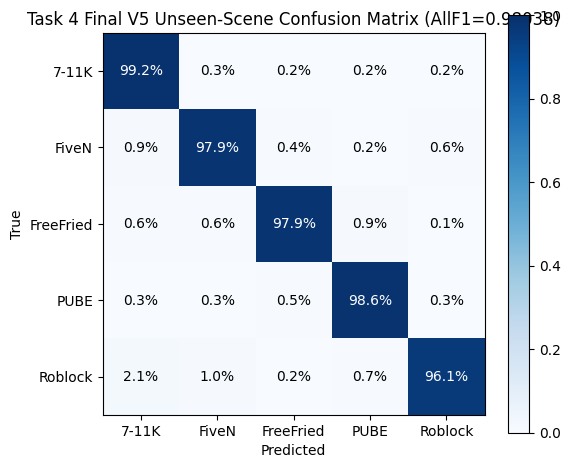


Saved Task 4 final submission to: /content/task4_cloud_out/sub_task4.csv
Test Class Counts: {np.int64(0): np.int64(4195), np.int64(1): np.int64(6000), np.int64(2): np.int64(3989), np.int64(3): np.int64(6713), np.int64(4): np.int64(4992)}


In [9]:
# [Cell 8] Phase 3 Final: PyTorch L-BFGS Temperature Calibration & 3-Paradigm Logit Blend -> sub_task4.csv
def temp_scale_oof_test(po: np.ndarray, pt: np.ndarray, y: np.ndarray, folds_arr: np.ndarray, w_bal_cls: np.ndarray):
    """PyTorch L-BFGS 1-parameter temperature calibration fitted strictly out-of-fold on folds_scene."""
    cal_o = np.zeros_like(po, dtype=np.float32)
    cal_t = np.zeros_like(pt, dtype=np.float32)
    temps = []
    lo = torch.from_numpy(np.log(np.clip(po, 1e-6, 1.0))).float()
    lt = torch.from_numpy(np.log(np.clip(pt, 1e-6, 1.0))).float()
    yt = torch.from_numpy(y).long()
    w_t = torch.from_numpy(w_bal_cls).float()
    for f in range(5):
        tr_m, va_m = folds_arr != f, folds_arr == f
        log_T = torch.nn.Parameter(torch.zeros(1))
        opt = torch.optim.LBFGS([log_T], lr=0.2, max_iter=35)

        def closure():
            opt.zero_grad()
            T = torch.exp(log_T).clamp(0.3, 3.0)
            lp = torch.log_softmax(lo[tr_m] / T, dim=-1)
            loss = -(lp[torch.arange(tr_m.sum()), yt[tr_m]] * w_t[yt[tr_m]]).mean()
            loss.backward()
            return loss

        opt.step(closure)
        T_val = float(torch.exp(log_T).clamp(0.3, 3.0).item())
        temps.append(T_val)
        with torch.no_grad():
            cal_o[va_m] = torch.softmax(lo[va_m] / T_val, dim=-1).numpy()
            cal_t += torch.softmax(lt / T_val, dim=-1).numpy() / 5.0
    return cal_o, cal_t, float(np.mean(temps))


pi_cls = np.bincount(y_all) / len(y_all)
w_bal_cls = (1.0 / (pi_cls ** 0.50)).astype(np.float32)
w_bal_cls /= w_bal_cls.mean()
sample_w_bal = w_bal_cls[y_all]

family_models = {
    "v5_convnext_small": (oof_cnx, te_cnx),
    "v5_swin_tiny":      (oof_swin, te_swin),
    "v4_cloud5_mlp":     (oof_v4_mlp, test_v4_mlp),
}

cal_models = {}
print("=" * 88)
print("[Phase 3] Out-of-Fold PyTorch L-BFGS Temperature Calibration (Golden Unseen-Scene 5-Fold)")
print("=" * 88)
for mn, (po, pt) in family_models.items():
    assert not np.isnan(po).any() and not np.isnan(pt).any()
    co, ct, mean_t = temp_scale_oof_test(po, pt, y_all, folds_scene, w_bal_cls)
    cal_models[mn] = (co, ct)
    ll0 = log_loss(y_all, po, sample_weight=sample_w_bal)
    ll1 = log_loss(y_all, co, sample_weight=sample_w_bal)
    print(f"  {mn:<18s} | mean_T={mean_t:.3f} | BalLogLoss: {ll0:.4f} -> {ll1:.4f} | UnseenAllF1={f1_score(y_all, co.argmax(1), average='macro'):.5f}")

# Winning 3-Family Calibrated Logit Blend: 0.50*ConvNeXt-Small + 0.35*Swin-Tiny + 0.15*5-Foundation MLP
w_3f = {"v5_convnext_small": 0.50, "v5_swin_tiny": 0.35, "v4_cloud5_mlp": 0.15}
lo_3f = sum(wt * np.log(np.clip(cal_models[mn][0], 1e-6, 1.0)) for mn, wt in w_3f.items())
lt_3f = sum(wt * np.log(np.clip(cal_models[mn][1], 1e-6, 1.0)) for mn, wt in w_3f.items())
lo_3f -= lo_3f.max(axis=1, keepdims=True)
lt_3f -= lt_3f.max(axis=1, keepdims=True)
oof_final = (np.exp(lo_3f) / np.exp(lo_3f).sum(axis=1, keepdims=True)).astype(np.float32)
te_final = (np.exp(lt_3f) / np.exp(lt_3f).sum(axis=1, keepdims=True)).astype(np.float32)

print("\n" + "=" * 88)
print("FINAL GOLDEN UNSEEN-SCENE 5-FOLD BENCHMARK (ALL 3 PARADIGMS)")
print("=" * 88)
for mn in family_models:
    eval_unseen_report(f"{mn} (cal)", cal_models[mn][0])
eval_unseen_report("3-Family Final Logit", oof_final)

disagree = float((cal_models["v5_convnext_small"][1].argmax(1) != cal_models["v5_swin_tiny"][1].argmax(1)).mean() * 100.0)
print(f"\nTest Cross-Family Disagreement (ConvNeXt-Small vs Swin-Tiny): {disagree:.2f}%")
print(f"Test Mean Max-Confidence: {te_final.max(axis=1).mean():.4f}")

print("\nPer-Class Unseen-Scene Classification Report:")
print(classification_report(y_all, oof_final.argmax(1), target_names=["0: 7-11K", "1: FiveN", "2: FreeFried", "3: PUBE", "4: Roblock"], digits=4))

# Plot Unseen-Scene Normalized Confusion Matrix
cm = confusion_matrix(y_all, oof_final.argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
labels_cm = ["7-11K", "FiveN", "FreeFried", "PUBE", "Roblock"]
ax.set_xticks(range(5)); ax.set_xticklabels(labels_cm)
ax.set_yticks(range(5)); ax.set_yticklabels(labels_cm)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]*100:.1f}%", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_title(f"Task 4 Final V5 Unseen-Scene Confusion Matrix (AllF1={f1_score(y_all, oof_final.argmax(1), average='macro'):.5f})")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# Export Final Submission: submissions/sub_task4.csv
pred_final = te_final.argmax(axis=1).astype(int)
sub_df = pd.DataFrame({"id": te_df["id"].values, "task4": pred_final})
assert len(sub_df) == 25889 and not sub_df.isna().any().any() and set(sub_df["task4"].unique()).issubset({0, 1, 2, 3, 4})

sub_path = os.path.join(SUB_DIR, "sub_task4.csv")
sub_df.to_csv(sub_path, index=False)
print(f"\nSaved Task 4 final submission to: {sub_path}")
print("Test Class Counts:", dict(zip(*np.unique(pred_final, return_counts=True))))